# Блок 7. Основы искусственного интеллекта и машинного обучения
## Занятие 9. Кластеризация и алгоритм K-Means

## Что такое кластеризация

До этого мы решали задачи обучения с учителем:

- регрессия;
- классификация.

Там были правильные ответы (целевая переменная).

Кластеризация относится к обучению без учителя.

Алгоритм сам пытается найти группы объектов.

---

## Примеры кластеризации

### Маркетинг

Поиск групп клиентов:

- экономные;
- премиальные;
- постоянные.

### Недвижимость

Поиск районов со схожими характеристиками.

### Спорт

Поиск типов спортсменов.

### Финансы

Поиск типов клиентов банка.

---

## Что такое K-Means

K-Means делит объекты на K групп.

Алгоритм:

1. Выбираем количество кластеров K.
2. Создаем центры кластеров.
3. Распределяем объекты.
4. Пересчитываем центры.
5. Повторяем до стабилизации.

---

## Что изучаем

- K-Means;
- масштабирование данных;
- центры кластеров;
- визуализацию кластеров;
- подбор числа кластеров;
- метод локтя (Elbow Method).

---

## Связь с дипломом

Кластеризация используется:

- сегментация клиентов;
- анализ покупателей;
- анализ спортсменов;
- анализ недвижимости;
- анализ финансовых данных.


Сначала изучите SOLVED-ноутбук вместе с преподавателем, затем выполните TODO самостоятельно.

## Ячейка 1. Создание датасета клиентов

### Алгоритм
Создаем искусственные данные клиентов магазина.

In [6]:
import pandas as pd
import numpy as np

np.random.seed(72)

df = pd.DataFrame({
    "income": np.random.randint(40000, 120000, 500),
    "spending": np.random.randint(5000, 50000, 500)
})

display(df.head())

assert len(df) == 500

,income,spending
0,118296,28389
1,103251,17270
2,110702,38602
3,47242,40060
4,108421,8089


## Ячейка 2. Визуализация данных

### Алгоритм
Смотрим клиентов на плоскости.

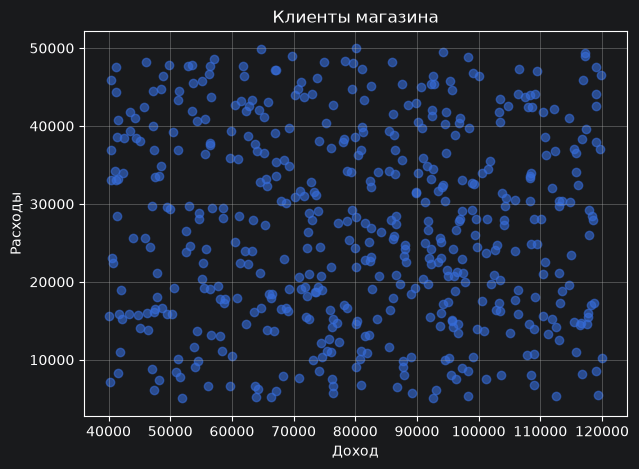

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(df["income"], df["spending"], alpha=0.6)
plt.xlabel("Доход")
plt.ylabel("Расходы")
plt.title("Клиенты магазина")
plt.grid(True)
plt.show()

assert True

## Ячейка 3. Подготовка признаков

### Алгоритм
Выделяем признаки для кластеризации.

In [8]:
X = df[["income", "spending"]]

print(X.shape)

assert X.shape[1] == 2

(500, 2)


## Ячейка 4. Масштабирование

### Алгоритм
Приводим признаки к одному масштабу.

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

assert X_scaled.shape[0] == len(df)

## Ячейка 5. Первый K-Means

### Алгоритм
Строим модель с тремя кластерами.

In [10]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

assert kmeans is not None

## Ячейка 6. Метки кластеров

### Алгоритм
Получаем номера кластеров.

In [16]:
clusters = kmeans.labels_

df["cluster"] = clusters

print(df["cluster"].value_counts())

assert len(df["cluster"].unique() == 3)

cluster
1    201
2    160
0    139
Name: count, dtype: int64


## Ячейка 7. Визуализация кластеров

### Алгоритм
Показываем найденные группы.

Text(0.5, 1.0, 'Кластеры клиентов')

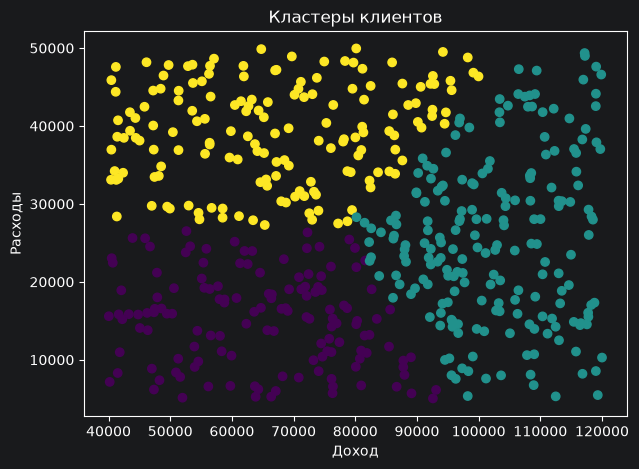

In [17]:
plt.figure(figsize=(7, 5))
plt.scatter(
    df["income"],
    df["spending"],
    c=df["cluster"]
)

plt.xlabel("Доход")
plt.ylabel("Расходы")
plt.title("Кластеры клиентов")


## Ячейка 8. Метод локтя

### Алгоритм
Подбираем количество кластеров.

In [18]:
inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=72,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)

assert len(inertia) == 10

## Ячейка 9. График метода локтя

### Алгоритм
Анализируем количество кластеров.

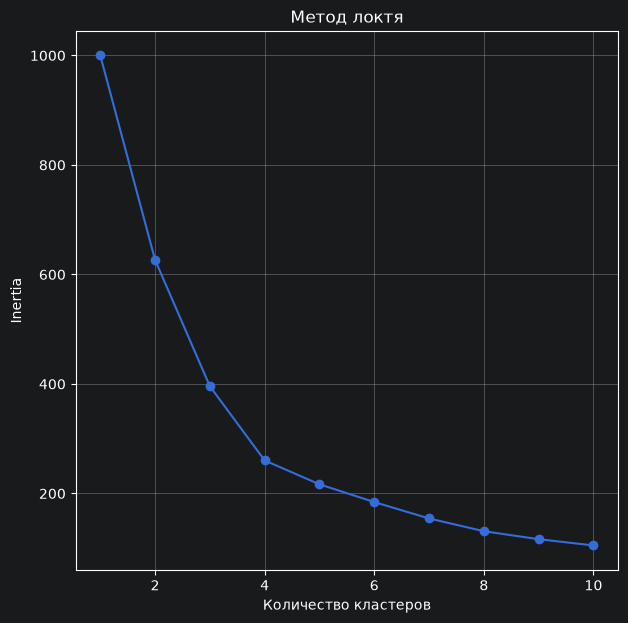

In [19]:
plt.figure(figsize=(7,7))
plt.plot(range(1,11), inertia, marker="o")
plt.xlabel("Количество кластеров")
plt.ylabel("Inertia")
plt.title("Метод локтя")
plt.grid(True)


## Ячейка 10. Мини-проект

### Алгоритм
Формируем аналитический отчет.

In [20]:
report = {
    "rows": len(df),
    "clusters": len(df["cluster"].unique()),
    "avg_income": round(df["income"].mean(),2),
    "avg_spending": round(df["spending"].mean(),2)
}

print(report)

assert report["clusters"]==3

{'rows': 500, 'clusters': 3, 'avg_income': np.float64(80688.26), 'avg_spending': np.float64(27007.85)}
